# Pandas 4: Time Series

**Seong Cho** · ACME Data Science Essentials, Lab 10

**Lab objective:** use pandas to clean and manipulate time-stamped data (stock prices, paychecks, quarterly finances, website visits) and apply some basic tools of time series analysis.

<sub>Lab specification from the *Data Science Essentials* lab manual of [Foundations of Applied Mathematics](https://foundations-of-applied-mathematics.github.io/) (BYU ACME), © Dr. J. Humpherys, used under [CC BY 3.0 US](http://creativecommons.org/licenses/by/3.0/us/). Problem statements are quoted from the course's lab template; the notes are condensed from the spec. Solutions are my own.</sub>

In [1]:
# Volume 3: Pandas IV (Time Series).
#     <Name>
#     <Class>
#     <Date>

import pandas as pd
from matplotlib import pyplot as plt
%matplotlib inline

# Matplotlib customizations.
# plt.style.use("ggplot")                       # Use a different style.
plt.rcParams["figure.figsize"] = [10.0, 6.0]  # Make figures larger by default.
plt.rcParams["figure.dpi"] = 100              # Raise figure quality within the notebook.
# Changed: dpi 200 -> 100 to keep the notebook small (about 2.5 MB at 200); in my original run
# these rcParams did not take effect and the figures came out at the 72-dpi default.

# Pandas customizations.
pd.set_option("display.max_rows", 250)        # Raise the number of rows displayed.
pd.set_option("display.max_columns", 50)      # Raise the number of columns displayed.
pd.set_option("display.precision", 3)         # Truncate floats to 3 decimals in data frames.  [compat] option was renamed

## Dates, times and a `DatetimeIndex`

`datetime.datetime(year, month, day[, hour, minute, second, microsecond])` from the standard library is a time stamp; `datetime.strptime(string, format)` parses one from a string with a format such as `"%m/%d//%Y::%H"` (`%Y`/`%y` 4- or 2-digit year, `%m` month, `%d` day, `%H`/`%I` 24- or 12-hour, `%M` minute, `%S` second). The pandas equivalent is the `Timestamp`; an index of them is a `DatetimeIndex`, and a `Series` or `DataFrame` with one is a **time series**. `pd.to_datetime()` converts a collection of dates to a `DatetimeIndex`, inferring the format if possible (or taking `format=`).

## Problem 1: The Dow Jones Industrial Average

> **Problem 1.** The file `DJIA.csv` contains daily closing values of the Dow Jones Industrial Average from 2006–2016.
> Read the data into a `Series` or `DataFrame` with a `DatetimeIndex` as the index.
> Drop rows with missing values, cast the `"VALUES"` column to floats, then plot the data.

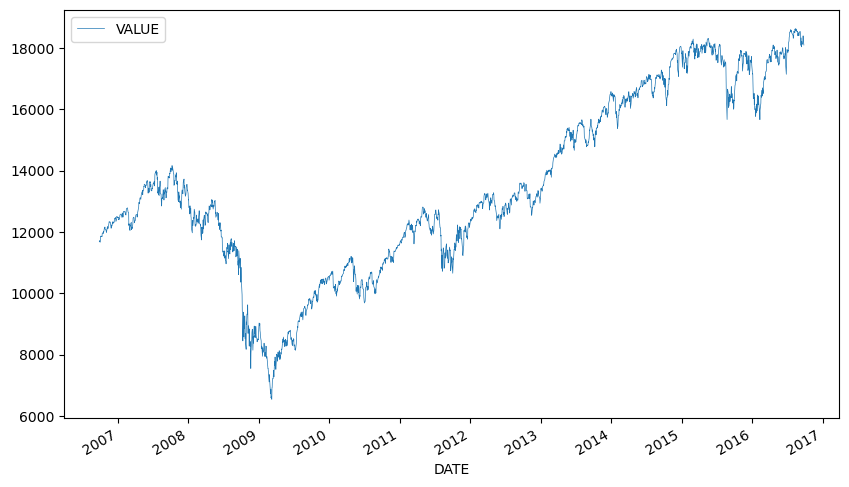

In [2]:
from datetime import datetime

djia = pd.read_csv("DJIA.csv", parse_dates=[0], index_col=0)

djia = djia.drop(djia[djia.VALUE=='.'].index)
djia.VALUE = djia.VALUE.astype(float)
djia.plot(lw=.5)
plt.show()

## Generating time-based indices

`pd.date_range()` builds an evenly spaced `DatetimeIndex`, like `np.arange()` for dates: give exactly two of `start`, `end` and `periods`, plus a `freq` **offset alias**, e.g. `"D"` (calendar day, default), `"B"` (business day), `"H"` (hourly), `"T"` (minutely), `"S"` (secondly), `"MS"` (first day of the month), `"BMS"` (first weekday of the month), `"W-MON"` (every Monday), `"WOM-3FRI"` (every 3rd Friday of the month). Aliases combine with multiples, e.g. `"2BMS"`, `"10T"` or `"2h30min"`; `normalize=True` trims the times to midnight.

## Problem 2: Paychecks

> **Problem 2.** The file `paychecks.csv` contains values of an hourly employee's last 93 paychecks.
> He started working March 13, 2008.
> This company hands out paychecks on the first and third Fridays of the month.
> Read in the data, using `pd.date_range()` to generate the DatetimeIndex.
> Plot the data.

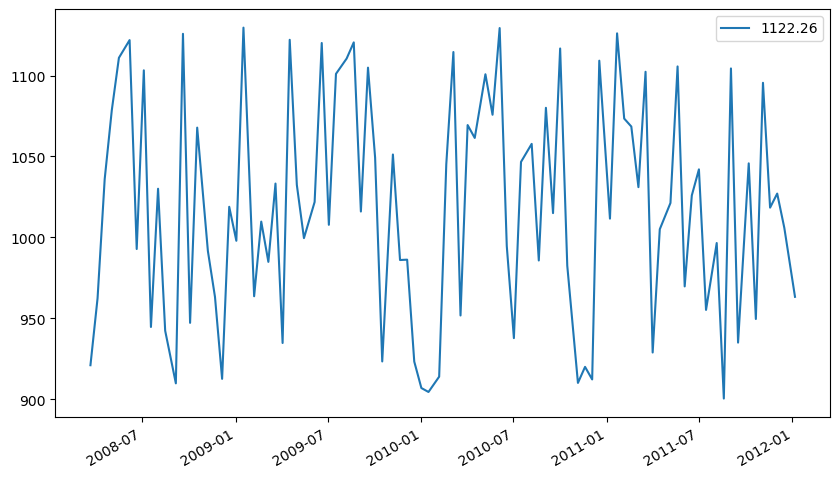

In [3]:
pc = pd.read_csv("paychecks.csv")
dr1 = pd.date_range(start='3/13/2008', periods=len(pc)//2, freq="WOM-3FRI")  # [compat] periods must be an int
dr2 = pd.date_range(start='3/13/2008', periods=len(pc)//2, freq="WOM-1FRI")  # [compat]
dates = dr1.union(dr2)
pc = pc.set_index(dates)
pc.plot()
plt.show()

## Periods

Data recorded over an interval (daily steps, weekly box-office earnings, quarterly earnings) is better labeled by a `Period` than an exact time stamp. `pd.Period(value, freq)` names the period containing `value`; its `freq` marks the *end* of the period, so `"Q-SEP"` means quarters with Q4 ending in September, and `start_time`/`end_time` give its bounds. `pd.period_range()` builds a `PeriodIndex` with the same syntax as `pd.date_range()`. `asfreq()` changes the frequency, adding an integer $n$ shifts the index by $n \times$ `freq`, and `to_timestamp()` / `to_period()` convert between the two kinds of index.

## Problem 3: Quarterly finances

> **Problem 3.** The file `finances.csv` contains a list of simulated quarterly earnings and expense totals from a fictional company.
> Load the data into a `Series` or `DataFrame` with a `PeriodIndex` with a quarterly frequency.
> Assume the fiscal year starts at the beginning of September and that the data begins in September 1978.
> Plot the data.

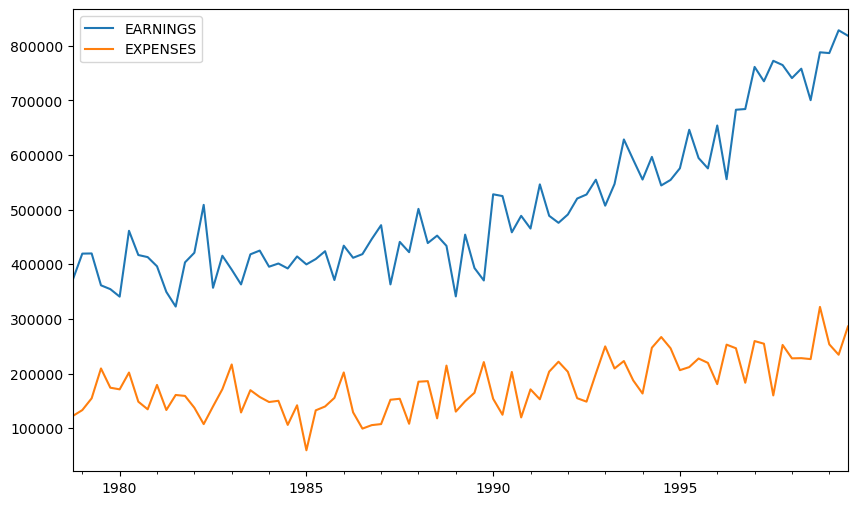

In [4]:
finances = pd.read_csv("finances.csv")
p = pd.period_range(start="9/1/1978", periods=len(finances), freq="Q-SEP")
finances = finances.set_index(p)
finances.plot()
plt.show()

## Slicing and resampling

A `DatetimeIndex` allows slicing by partial dates: `df.loc["2010"]` (a year), `df.loc["2010-07"]` (a month) or `df.loc["2010-07-01":"2010-07-15"]`. **Resampling** changes the frequency of irregular or high-frequency data: *downsampling* aggregates into fewer intervals and *upsampling* adds intervals. `resample(rule)` works like `groupby()` on time bins and needs an aggregation, e.g. `s.resample("A").mean()` for yearly means.

## Problem 4: Website traffic

> **Problem 4.** The file `website_traffic.csv` contains records for different visits to a fictitious website.
> Read in the data, calculate the duration of each visit (in seconds), and convert the index to a `DatetimeIndex`.
> Use downsampling to calculate the average visit duration by minute, and the average visit duration by hour.
> Plot both results on the same graph.

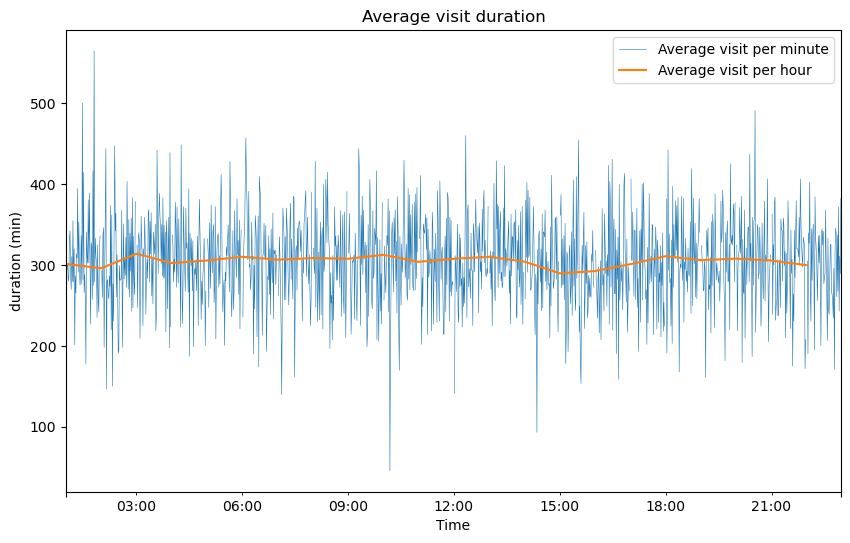

In [5]:
wt = pd.read_csv("website_traffic.csv")
index = pd.to_datetime(wt.ENTER)
duration = pd.to_datetime(wt.LEAVE) - pd.to_datetime(wt.ENTER)
dur = pd.Series([d.seconds for d in duration])
dur.index = index
# [compat] the "H" and "T" aliases are deprecated in pandas 2.2; "h" and "min" are the same frequencies
hour = dur.resample("h").mean()
minute = dur.resample("min").mean()
minute.plot(lw=.4, label="Average visit per minute")
hour.plot(label="Average visit per hour")
plt.legend()
plt.ylabel("duration (min)")
plt.xlabel("Time")
plt.title("Average visit duration")
plt.show()

## Shifting

`shift(n)` moves the data up or down relative to the index (with `freq=`, it shifts the index itself by a time offset). Comparing a series with its shift, or calling `diff()`, gives the change from one time stamp or period to the next.

## Problem 5: Largest gains and losses

> **Problem 5.** Compute the following information about the DJIA dataset from Problem 1.
> - The single day with the largest gain.
> - The single day with the largest loss.
> - The month with the largest gain.
> - The month with the largest loss.
>
> For the monthly statistics, define the gain (or loss) to be the difference between the DJIA on the last and first days of the month.

In [6]:
diff = djia.diff()
max_gain = diff.max().VALUE
max_loss = diff.min().VALUE
print("The single day with the largest gain")
diff[diff.VALUE==max_gain]

The single day with the largest gain


,VALUE
DATE,
2008-10-13,936.42


In [7]:
print("The single day with the largest loss")
diff[diff.VALUE==max_loss]

The single day with the largest loss


,VALUE
DATE,
2008-09-29,-777.68


In [8]:
month_diff = pd.DataFrame(columns=["date", "value"])
for year in range(2006, 2017):
    for month in range(1, 13):
        date = str(year) + "-" + str(month)
        try:
            val = djia.loc[date].iloc[-1] - djia.loc[date].iloc[0]  # [compat] row selection by a date string needs .loc in pandas 2.x
            month_diff.loc[len(month_diff)] = [date, val.VALUE]  # [compat] DataFrame.append was removed in pandas 2.0
        except KeyError:
            continue
month_diff = month_diff.set_index(month_diff.date).drop(columns=['date'])
max_gain = month_diff.max().value
max_loss = month_diff.min().value
print("The month with the largest gain")
month_diff[month_diff.value==max_gain]

The month with the largest gain


,value
date,
2015-10,1391.53


In [9]:
print("The month with the largest loss")
month_diff[month_diff.value==max_loss]

The month with the largest loss


,value
date,
2008-10,-1506.06


## Rolling and exponentially weighted functions

Many time series are noisy; rolling and EWM functions show the general trend. A **rolling** (moving-window) function computes a statistic over a window of the data: `s.rolling(window=200)` returns a window object to aggregate with `mean()`, `std()`, `var()`, `min()`, `max()`, and so on. An **exponentially weighted moving** (EWM) function instead weights recent points more heavily. For the EWM average (EWMA),

$$z_i = \alpha \bar{x}_i + (1 - \alpha) z_{i-1},$$

where $z_i$ is the EWMA at time $i$, $\bar{x}_i$ the average of the $i$-th window, and $\alpha$ the decay factor; $\alpha = 1$ reduces to the rolling average. The decay is usually given through the window size: `s.ewm(span=200).mean()`, where `span` is nearly analogous to a rolling window.

## Problem 6: Rolling and EWM views of the DJIA

> **Problem 6.** Plot the following from the DJIA dataset with a window or span of 30, 120, and 365.
> - The original data points.
> - Rolling average.
> - Exponential average.
> - Minimum rolling values.
> - Maximum rolling values.
>
> Describe how varying the length of the window changes the approximation to the data.

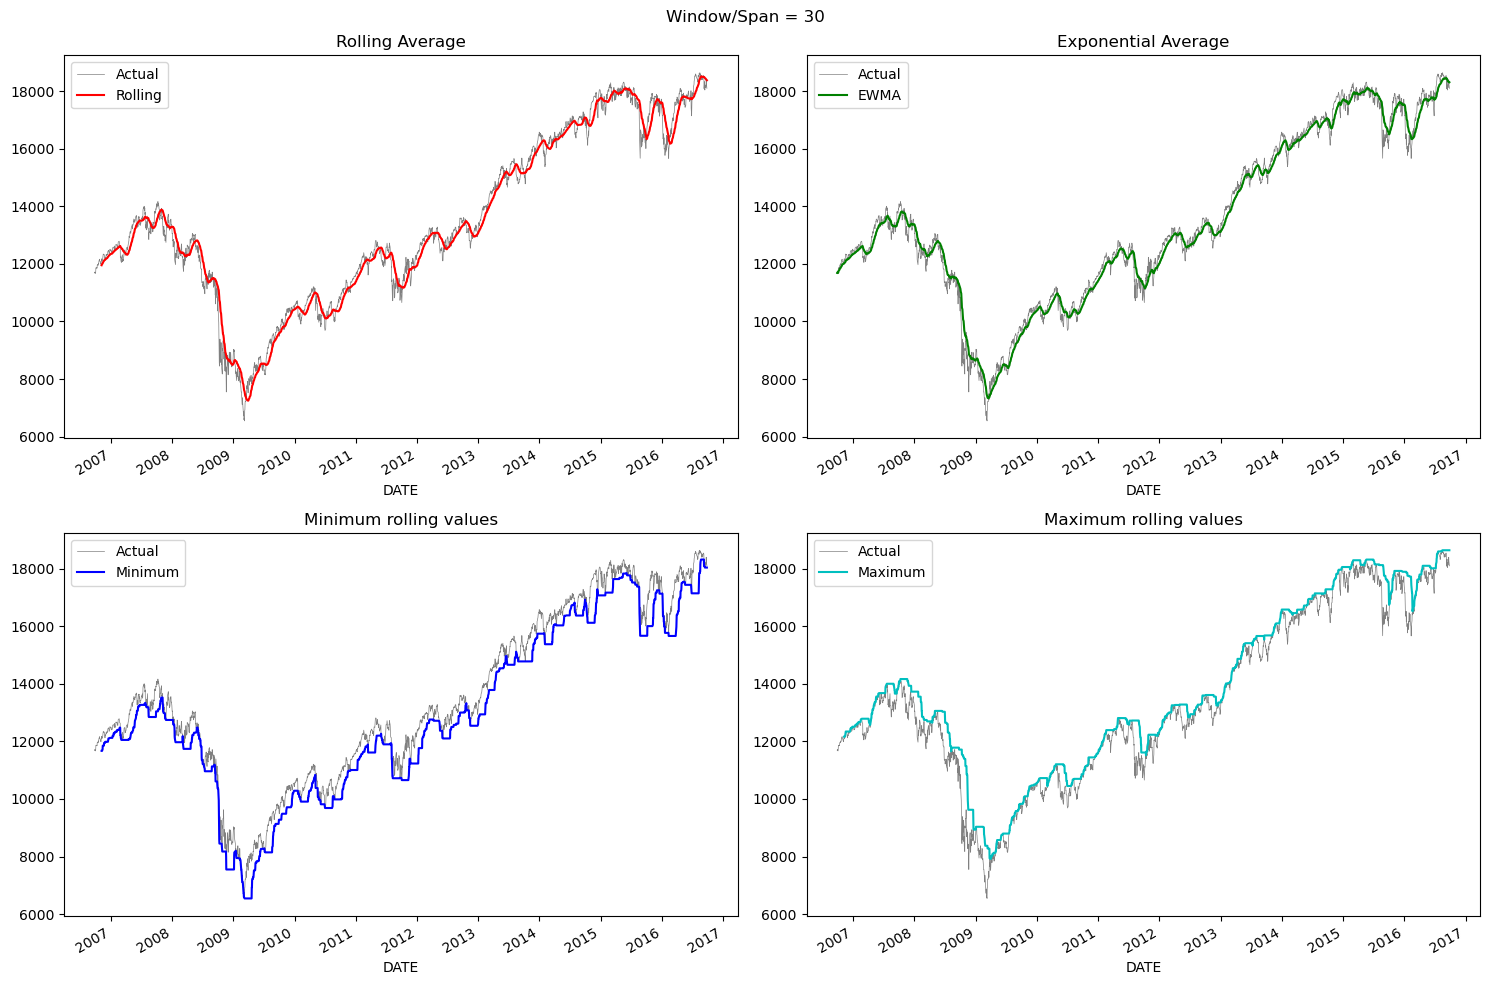

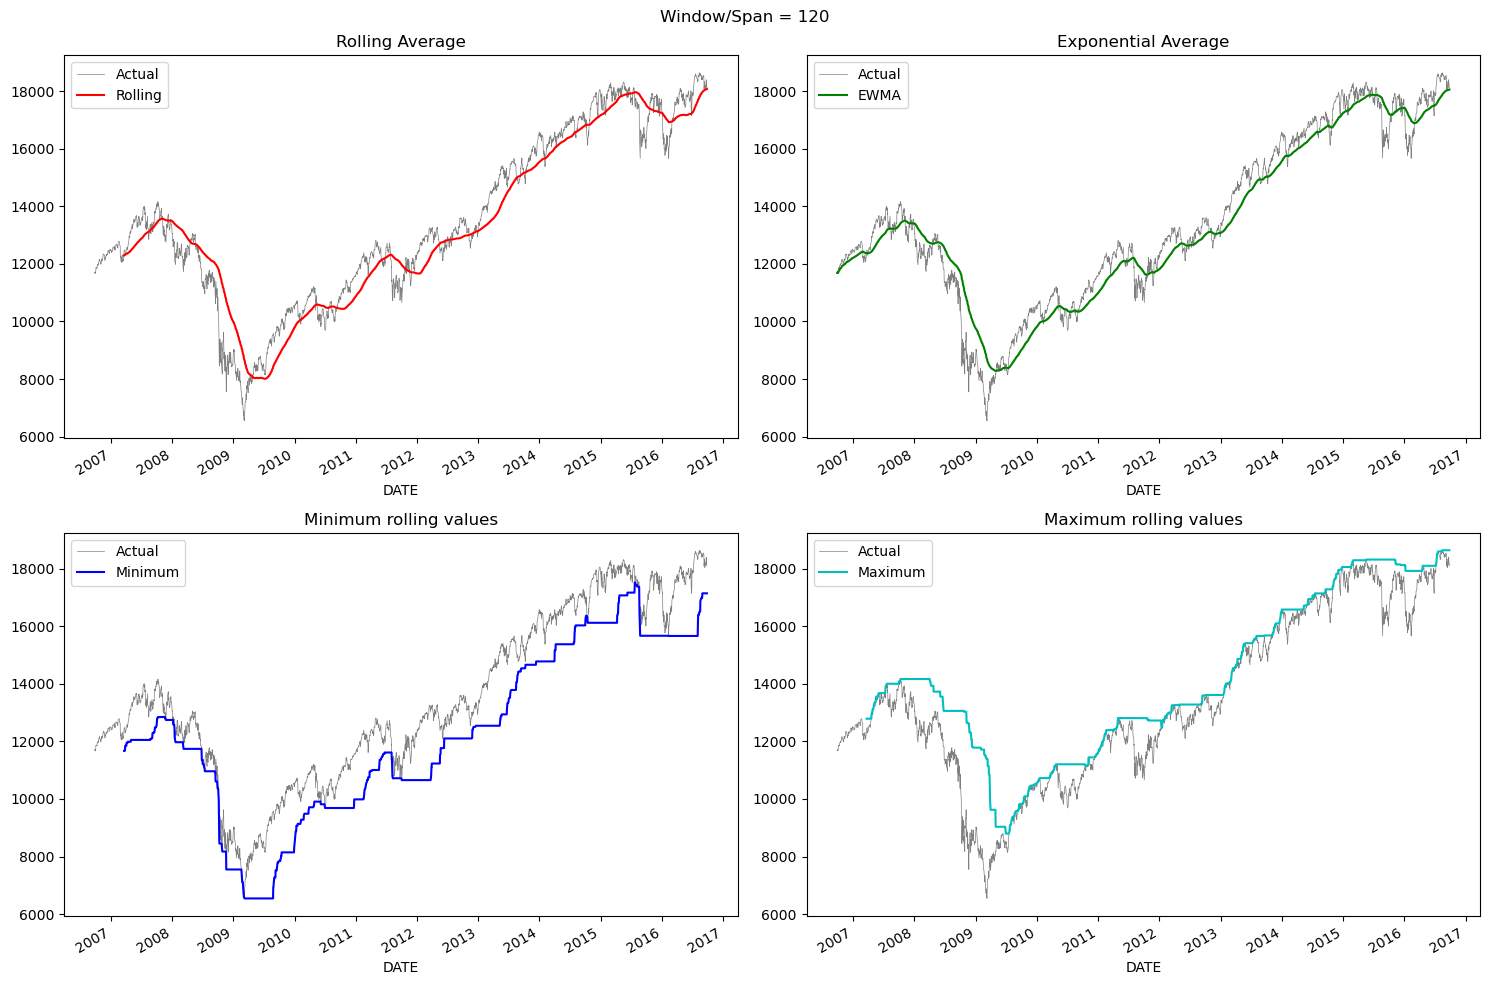

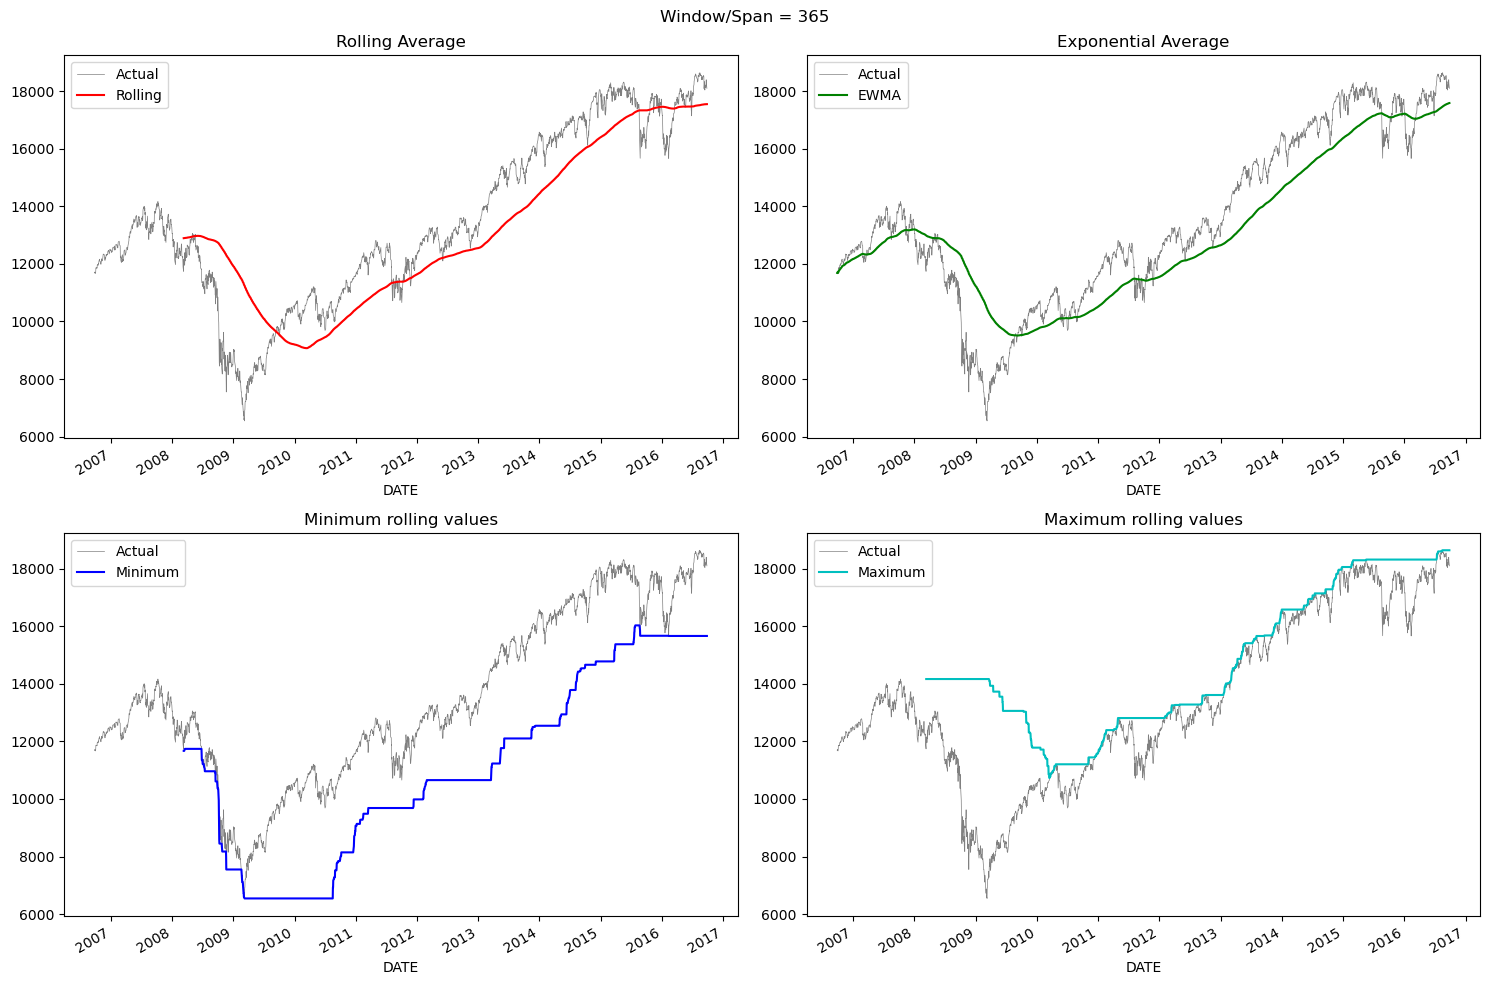

In [10]:
for n in [30, 120, 365]:
    fig = plt.figure(figsize=(15,10))
    ax1 = plt.subplot(221)
    djia.plot(color="gray", lw=.5, ax=ax1)
    djia.rolling(window=n).mean().plot(color='r', ax=ax1)
    plt.title("Rolling Average")
    ax1.legend(["Actual", "Rolling"])
    
    ax2 = plt.subplot(222)
    djia.plot(color="gray", lw=.5, ax=ax2)
    djia.ewm(span=n).mean().plot(color='g', ax=ax2)
    plt.title("Exponential Average")
    ax2.legend(["Actual", "EWMA"])
    
    ax3 = plt.subplot(223)
    djia.plot(color="gray", lw=.5, ax=ax3)
    djia.rolling(window=n).min().plot(color='b', ax=ax3)
    plt.title("Minimum rolling values")
    ax3.legend(["Actual", "Minimum"])
    
    ax4 = plt.subplot(224)
    djia.plot(color="gray", lw=.5, ax=ax4)
    djia.rolling(window=n).max().plot(color='c', ax=ax4)
    plt.title("Maximum rolling values")
    ax4.legend(["Actual", "Maximum"])
    plt.suptitle("Window/Span = " + str(n))
    plt.tight_layout()
    plt.show()

The varying lengths of the window eliminates noise and smoothes out the figure.